In [87]:
# Import analysis libraries.
import pandas as pd
import numpy as np
import scipy.stats as stats

# Import visualization libraries.
import matplotlib.pyplot as plt
import seaborn as sns

# Import engine connection file.
from _01_database_connection import engine

In [88]:
# Q1: Are the monthly revenue stable or volatile?

In [89]:
# Read the data from the database.
fact_sales = pd.read_sql(
    sql="SELECT * FROM gold.fact_sales",
    con=engine
)

# Pick a sample.
fact_sales.sample(1)

,order_number,product_key,customer_key,order_date,ship_date,due_date,price,quantity,sales
36258,SO64706,5,17432,2013-08-21,2013-08-28,2013-09-02,159,1,159


### GRAIN: Each row represents an item within an order. ###

In [90]:
# Ckeck data types.
fact_sales.dtypes

# Change (order_data, ship_date, due_date) columns from int into datetime.
date_columns = ["order_date", "ship_date", "due_date"]
fact_sales[date_columns] = fact_sales[date_columns].astype("datetime64[s]")

# Create a column to hold the year-month date to group the data by.
fact_sales["year_month"] = fact_sales["order_date"].dt.to_period("M")

In [91]:
# Group the data by year-month to analyse by the month-leve and, aggregate the sales.
monthly_grouped_revenue = fact_sales.groupby(
    by="year_month"
)["sales"].sum()[:-1]

monthly_grouped_revenue

year_month
2011-01     469795
2011-02     466307
2011-03     485165
2011-04     502042
2011-05     561647
2011-06     737793
2011-07     596710
2011-08     614516
2011-09     603047
2011-10     708164
2011-11     660507
2011-12     669395
2012-01     495363
2012-02     506992
2012-03     373478
2012-04     400324
2012-05     358866
2012-06     555142
2012-07     444533
2012-08     523887
2012-09     486149
2012-10     535125
2012-11     537918
2012-12     624454
2013-01     857758
2013-02     771218
2013-03    1049732
2013-04    1045860
2013-05    1284456
2013-06    1642948
2013-07    1371595
2013-08    1545910
2013-09    1447324
2013-10    1673261
2013-11    1780688
2013-12    1874128
Freq: M, Name: sales, dtype: int64

In [92]:
# Initialize the measures to calculate the dispersion (mean, median, std, cv, Q1, Q2, Q3, IQR, kurtosis, skewnwss, range and mad)
mean = monthly_grouped_revenue.mean() 
median = monthly_grouped_revenue.median() 
std = monthly_grouped_revenue.std(ddof=0) 
cv = (std / mean) * 100
Q1 = np.percentile(a=monthly_grouped_revenue, q=25) 
Q3 = np.percentile(a=monthly_grouped_revenue, q=75)
IQR = Q3 - Q1 
kur = stats.kurtosis(monthly_grouped_revenue, fisher=True)
ske = stats.skew(monthly_grouped_revenue)
sales_range = monthly_grouped_revenue.max() - monthly_grouped_revenue.min()
mad = stats.median_abs_deviation(monthly_grouped_revenue) 
diff_mean_median = mean - median

# Show the result.
print(f"""
Mean: {mean:.2f}
Median: {median:.2f}
STD: {std:.2f}
CV: {cv:.2f}
IQR: {IQR:.2f}
Q1: {Q1:.2f}
Q3: {Q3:.2f}
Kurtosis: {kur:.2f}
Skewness: {ske:.2f}
Sales_range: {sales_range:.2f}
MAD: {mad:.2f}
Diff_mean_median: {diff_mean_median:.2f}

""")


Mean: 812838.81
Median: 608781.50
STD: 444740.61
CV: 54.71
IQR: 546455.75
Q1: 500372.25
Q3: 1046828.00
Kurtosis: -0.15
Skewness: 1.13
Sales_range: 1515262.00
MAD: 133999.00
Diff_mean_median: 204057.31




Conclusion

Monthly revenue is highly variable (CV = 54.7%), but the variability reflects growth, not random swings. Revenue was flat in 2011, dipped in 2012, then rose sharply in 2013, peaking at 1.87M in December. This pulls the mean (812.8K) well above the median (608.8K) and creates a moderate right skew (1.13). January 2014 was excluded as a partial month.

**Q2: What is the highest three months of the revenue and lowest three months of the revenue?**

In [93]:
# Filter the data to get the highest month.
highest_three_months = monthly_grouped_revenue.nlargest(3)
lowest_three_months = monthly_grouped_revenue.nsmallest(3)

# Show the resrult
print(f"""
highest_three_months: {highest_three_months}
lowest_three_months: {lowest_three_months}
""")


highest_three_months: year_month
2013-12    1874128
2013-11    1780688
2013-10    1673261
Freq: M, Name: sales, dtype: int64
lowest_three_months: year_month
2012-05    358866
2012-03    373478
2012-04    400324
Freq: M, Name: sales, dtype: int64



**Q3: Plot the monthly revenue curve?**

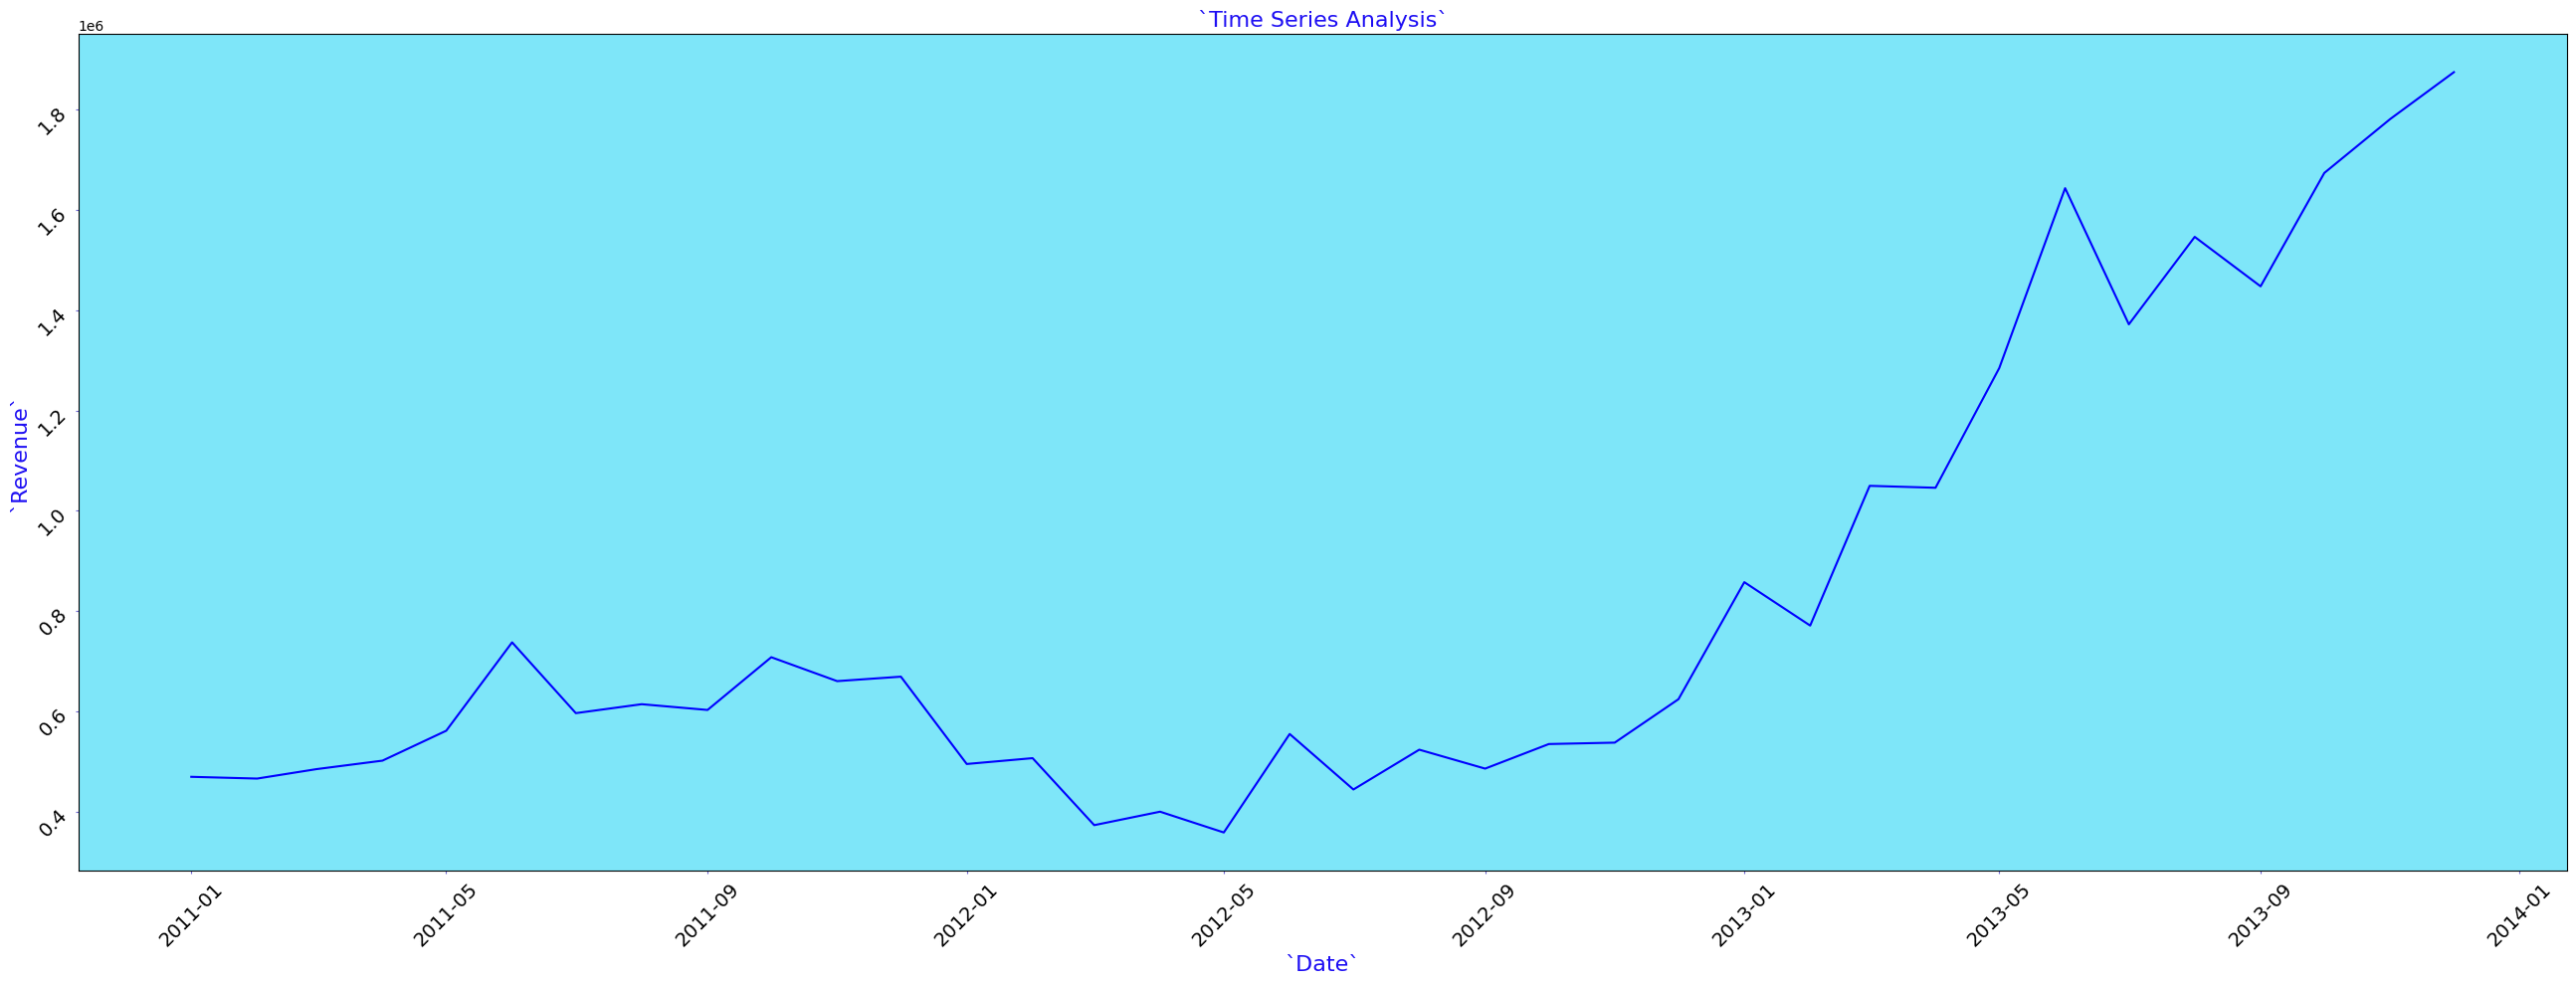

In [94]:
fig, ax = plt.subplots(figsize=(26, 10))

sns.lineplot(
    x=monthly_grouped_revenue.index.to_timestamp(),
    y=monthly_grouped_revenue,
    color="b",
    ax=ax
);

# Set labels.
ax.set_title("`Time Series Analysis`", color="#1D0EF3", fontsize=16);
ax.set_xlabel("`Date`", color="#1D0EF3", fontsize=16);
ax.set_ylabel("`Revenue`", color="#1D0EF3", fontsize=16);
ax.tick_params("both", rotation=45, color="#6D66D3", length=2, labelsize=14);

ax.set_facecolor("#7EE6F9");
plt.tight_layout();

**Q4: Does the relative dispersion of the revenue increase over time?**

In [95]:
# Using percentage change of monthly revenue to chick the growth.
def mad_calculator(x):
    """Takes a value and return the median abs deviation"""
    return stats.median_abs_deviation(x)

 # Convert the series into df.
df_monthly_revenue = pd.DataFrame(monthly_grouped_revenue)

# Using rolling pct, std, mean, median, cv, and mad.
df_monthly_revenue["pct"] = df_monthly_revenue["sales"].pct_change()
df_monthly_revenue["rolling_std"] = df_monthly_revenue["sales"].rolling(window=2).std(ddof=0)
df_monthly_revenue["rolling_mean"] = df_monthly_revenue["sales"].rolling(window=2).mean()
df_monthly_revenue["rolling_median"] = df_monthly_revenue["sales"].rolling(window=2).median()
df_monthly_revenue["rolling_cv"] = df_monthly_revenue["rolling_std"] / df_monthly_revenue["rolling_mean"]
df_monthly_revenue["rolling_mad"] = df_monthly_revenue["sales"].rolling(window=6).apply(mad_calculator)
df_monthly_revenue

,sales,pct,rolling_std,rolling_mean,rolling_median,rolling_cv,rolling_mad
year_month,,,,,,,
2011-01,469795,NaN,NaN,NaN,NaN,NaN,NaN
2011-02,466307,-0.007425,1744.0,468051.0,468051.0,0.003726,NaN
2011-03,485165,0.040441,9429.0,475736.0,475736.0,0.019820,NaN
2011-04,502042,0.034786,8438.5,493603.5,493603.5,0.017096,NaN
2011-05,561647,0.118725,29802.5,531844.5,531844.5,0.056036,NaN
2011-06,737793,0.313624,88073.0,649720.0,649720.0,0.135555,25552.5
2011-07,596710,-0.191223,70541.5,667251.5,667251.5,0.105720,55772.5
2011-08,614516,0.029840,8903.0,605613.0,605613.0,0.014701,56237.0
2011-09,603047,-0.018663,5734.5,608781.5,608781.5,0.009420,26434.5


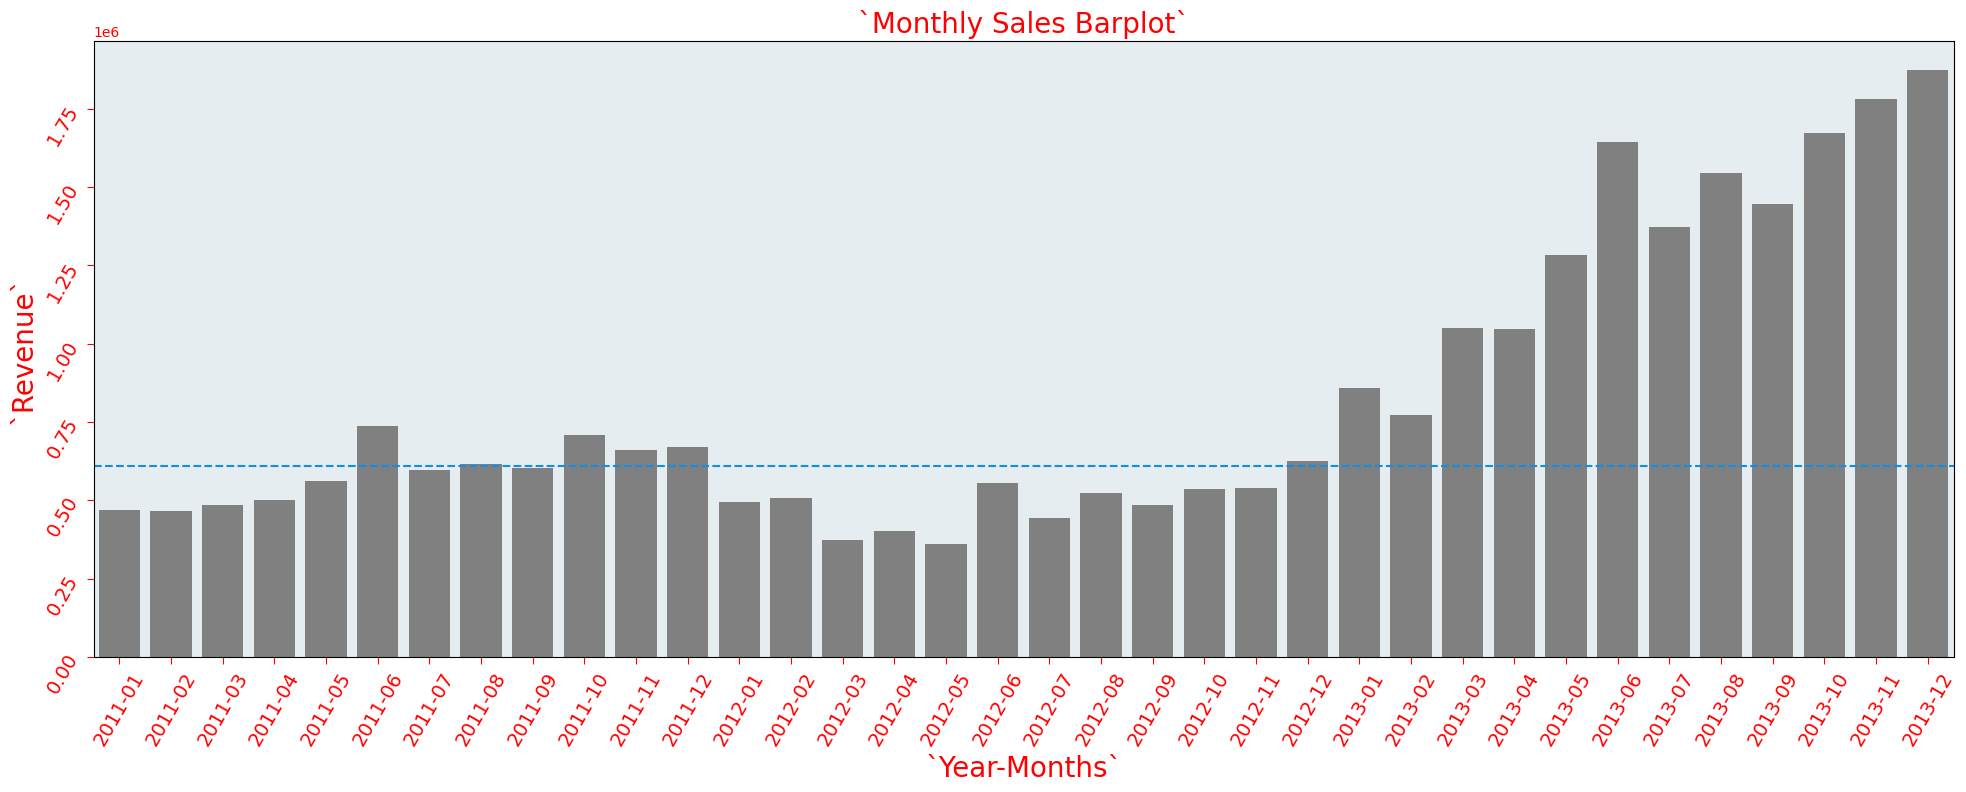

In [96]:
# Ploting a column bar to show the monthly sales.

fig, ax = plt.subplots(figsize=(24, 8))

sns.barplot(
    x=monthly_grouped_revenue.index,
    y=monthly_grouped_revenue,
    color="gray"
);
 
# Set labels.
ax.set_title("`Monthly Sales Barplot`", color="r", fontsize=20);
ax.set_xlabel("`Year-Months`", color="r", fontsize=20);
ax.set_ylabel("`Revenue`", color="r", fontsize=20);
ax.tick_params("both", rotation=60, length=5, color="r", labelsize=14, labelcolor="r");
ax.axhline(median, ls="--", c="#0F8FEA");
ax.set_facecolor("#E5EDF1");